# 03 - Differential Expression Analysis

This notebook compares **Cancer** with **Healthy** samples using pyDESeq2. It loads the filtered raw integer count matrix saved by `02_data_qc.ipynb` as `data/processed/raw_merged_filtered.csv`.

Differential expression can rank or select genes for dimensionality reduction. For unbiased ML evaluation, however, do **not** use genes selected by a DEA fitted on the full dataset before splitting: labels from the eventual test set would influence feature selection. Fit DEA separately using each training split (inside cross-validation) and apply that split's selected genes to its held-out samples.


In [1]:
import sys
sys.path.append('..')  # repository root when running from notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats


## 1. Load filtered raw counts and metadata

The filtered count matrix should have samples in rows and genes in columns, with the same sample identifiers as the metadata. pyDESeq2 requires raw integer counts; do not use the VST matrix as model input.

In [2]:
data_dir = '../data/processed'

counts_filtered = pd.read_csv(
    f'{data_dir}/raw_merged_filtered.csv',
    index_col=0,
)
metadata = pd.read_csv(
    f'{data_dir}/metadata_merged.csv',
    index_col=0,
)

if not counts_filtered.index.is_unique or not metadata.index.is_unique:
    raise ValueError('Sample identifiers must be unique in counts and metadata.')
if not counts_filtered.index.isin(metadata.index).all():
    raise ValueError('Some count-matrix samples are missing from metadata.')
if 'Condition' not in metadata.columns:
    raise ValueError('Metadata must contain a Condition column.')

# Keep samples in count-matrix order and align metadata exactly.
metadata = metadata.loc[counts_filtered.index].copy()
assert metadata.index.equals(counts_filtered.index)

print(f'Filtered count matrix shape (samples, genes): {counts_filtered.shape}')
display(metadata['Condition'].value_counts())


Filtered count matrix shape (samples, genes): (232, 27249)


Condition
Cancer     119
Healthy    113
Name: count, dtype: int64

## 2. Fit the pyDESeq2 model

The design includes condition only because the available metadata contains no batch covariate. If known batch or other covariates are available, review the design before interpreting results.

In [9]:
metadata['Condition'] = pd.Categorical(
    metadata['Condition'],
    categories=['Healthy', 'Cancer']
)

dds = DeseqDataSet(
    counts=counts_filtered,
    metadata=metadata,
    design='~Condition',
    refit_cooks=True,
    n_cpus=4,
)
dds.deseq2()

# Cancer versus Healthy: positive log2FoldChange indicates higher expression in Cancer.
stat_res = DeseqStats(
    dds,
    contrast=['Condition', 'Cancer', 'Healthy'],
    lfc_null=1.0,
    alt_hypothesis='greaterAbs',
)
stat_res.summary()
stat_res.lfc_shrink(coeff='Condition[T.Cancer]')
results = stat_res.results_df.sort_values('padj', na_position='last').copy()
display(results.head())


Fitting size factors...
... done in 0.15 seconds.



Using None as control genes, passed at DeseqDataSet initialization


Fitting dispersions...
... done in 4.89 seconds.

Fitting dispersion trend curve...
... done in 0.30 seconds.

Fitting MAP dispersions...
... done in 5.28 seconds.

Fitting LFCs...
... done in 2.79 seconds.

Calculating cook's distance...
... done in 0.29 seconds.

Replacing 2885 outlier genes.

Fitting dispersions...
... done in 0.55 seconds.

Fitting MAP dispersions...
... done in 0.52 seconds.

Fitting LFCs...
... done in 0.39 seconds.

Running Wald tests...
... done in 3.41 seconds.

Fitting MAP LFCs...


Log2 fold change & Wald test p-value: Condition Cancer vs Healthy
              baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
A1BG         16.044236        0.470633  0.107385  0.000000  1.000000  1.000000
A1BG-AS1     95.549057        0.501184  0.086486  0.000000  1.000000  1.000000
A1CF          5.318617        0.244646  0.243927  0.000000  1.000000  1.000000
A2M       75244.496108       -0.836253  0.094264  0.000000  1.000000  1.000000
A2M-AS1     154.415627       -1.128216  0.090578 -1.415541  0.156910  0.870448
...                ...             ...       ...       ...       ...       ...
ZYG11A      290.652658        1.648070  0.155450  4.169003  0.000031  0.000316
ZYG11B     3942.728633       -0.214592  0.071971  0.000000  1.000000  1.000000
ZYX       11648.952548       -0.433197  0.081100  0.000000  1.000000  1.000000
ZZEF1      5446.435512       -0.243368  0.052579  0.000000  1.000000  1.000000
ZZZ3       4211.383582       -0.015097  0.059058  0.000000  1.000

... done in 1.85 seconds.



,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
COL10A1,5737.098063,7.149793,0.181477,33.931661,2.274192e-252,6.196945e-248
MMP11,15056.037054,6.158534,0.171538,30.259632,3.897113e-201,5.309621e-197
COL11A1,8119.861826,6.211962,0.207093,25.242583,1.366199e-140,1.240919e-136
LINC01614,212.217760,5.611403,0.202901,22.816035,3.178456e-115,2.165243e-111
PLPP4,305.603667,4.893639,0.193464,20.202820,9.246375e-91,5.039089e-87


## 3. Summarize, select, and save results

Results include the estimated log2 fold change, standard error, test statistic, p-value, and Benjamini-Hochberg adjusted p-value. The following section uses adjusted p-value < 0.05 as the gene selection rule. For ML performance estimates, repeat this feature-selection step using training data only within each split.

In [10]:
alpha = 0.05
significant = results['padj'].notna() & (results['padj'] < alpha)
selected_genes = results.index[significant]

print(f'Genes tested: {len(results):,}')
print(f'Genes with adjusted p-value < {alpha}: {len(selected_genes):,}')
print('Top results by adjusted p-value:')
display(results.loc[significant].head(20))

results.to_csv(f'{data_dir}/differential_expression_cancer_vs_healthy.csv', index_label='gene')
pd.Series(selected_genes, name='gene').to_csv(
    f'{data_dir}/differential_expression_selected_genes_cancer_vs_healthy.csv',
    index=False,
)
print(f'Saved full results to {data_dir}/differential_expression_cancer_vs_healthy.csv')
print(f'Saved selected gene list to {data_dir}/differential_expression_selected_genes_cancer_vs_healthy.csv')


Genes tested: 27,249
Genes with adjusted p-value < 0.05: 3,691
Top results by adjusted p-value:


,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
COL10A1,5737.098063,7.149793,0.181477,33.931661,2.274192e-252,6.196945e-248
MMP11,15056.037054,6.158534,0.171538,30.259632,3.897113e-201,5.309621e-197
COL11A1,8119.861826,6.211962,0.207093,25.242583,1.366199e-140,1.240919e-136
LINC01614,212.217760,5.611403,0.202901,22.816035,3.178456e-115,2.165243e-111
PLPP4,305.603667,4.893639,0.193464,20.202820,9.246375e-91,5.039089e-87
CCN4,1685.416387,3.938660,0.146682,20.116691,5.271120e-90,2.393879e-86
SLC24A2,272.466349,5.285271,0.216249,19.921004,2.675720e-88,1.041581e-84
NEK2,1010.820350,4.249746,0.166013,19.659163,4.826214e-86,1.643869e-82
INHBA,3517.014587,3.578011,0.131945,19.636816,7.495287e-86,2.269323e-82
IBSP,107.492594,6.938458,0.304226,19.587798,1.965087e-85,5.354665e-82


Saved full results to ../data/processed/differential_expression_cancer_vs_healthy.csv
Saved selected gene list to ../data/processed/differential_expression_selected_genes_cancer_vs_healthy.csv


## 5. Volcano plot

The x-axis shows the Cancer versus Healthy log2 fold change. The y-axis shows the negative log10 adjusted p-value; genes without an adjusted p-value are omitted from the plot.

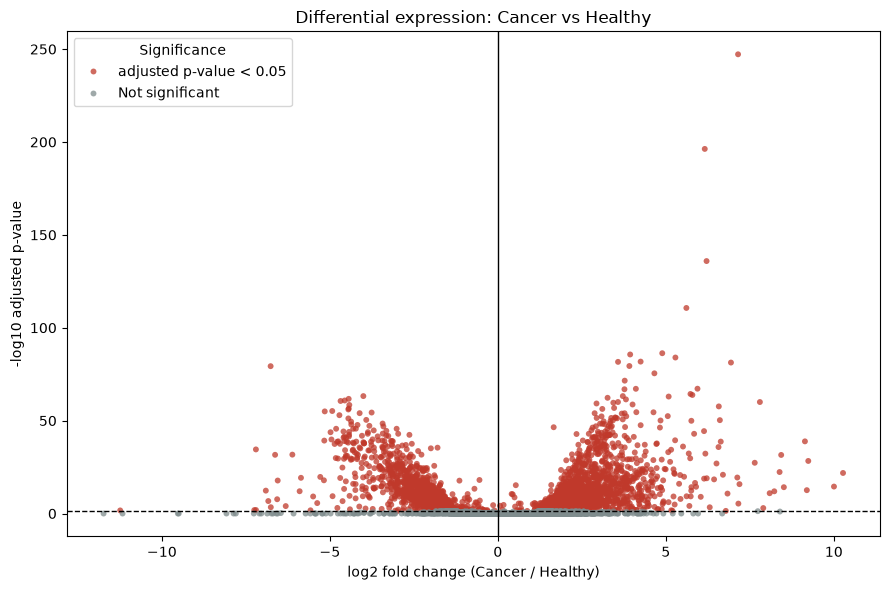

In [11]:
plot_df = results.dropna(subset=['padj', 'log2FoldChange']).copy()
plot_df['neg_log10_padj'] = -np.log10(plot_df['padj'].clip(lower=np.finfo(float).tiny))
plot_df['Significance'] = np.where(plot_df['padj'] < alpha, f'adjusted p-value < {alpha}', 'Not significant')

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(
    data=plot_df,
    x='log2FoldChange',
    y='neg_log10_padj',
    hue='Significance',
    hue_order=[f'adjusted p-value < {alpha}', 'Not significant'],
    palette={f'adjusted p-value < {alpha}': '#c0392b', 'Not significant': '#7f8c8d'},
    linewidth=0,
    s=18,
    alpha=0.75,
    ax=ax,
)
ax.axhline(-np.log10(alpha), color='black', linestyle='--', linewidth=1)
ax.axvline(0, color='black', linewidth=1)
ax.set(title='Differential expression: Cancer vs Healthy', xlabel='log2 fold change (Cancer / Healthy)', ylabel='-log10 adjusted p-value')
plt.tight_layout()
plt.show()


## Interpretation and ML notes

- Positive log2 fold changes indicate higher estimated expression in Cancer; negative values indicate higher expression in Healthy.
- Inference uses raw integer counts from `raw_merged_filtered.csv`, which already has the QC count threshold applied.
- The saved adjusted-p-value-selected gene list can support exploratory dimensionality reduction. Do not use this full-cohort list to report held-out ML performance: perform DEA and feature selection within each training split/fold, then transform the corresponding validation/test data using only those selected genes.
- The model uses condition alone. Interpret results with the available sample metadata and study design in mind.
